# DIP Super-Resolution with Two Independent Noise Vectors

**Goal:** Feed two independent noise tensors, `z1` and `z2`, into the **same shared DIP U-Net**. The network produces two HR reconstructions, and both reconstructions are trained against the **same observed low-resolution image**.

For each iteration:

- `x1 = net(z1)` and `x2 = net(z2)`
- `loss1 = L1(D(x1), y_lr)`
- `loss2 = L1(D(x2), y_lr)`
- `loss_data = 0.5 * (loss1 + loss2)`
- Optionally, `loss_consistency = L1(x1, x2)` encourages the two HR outputs to agree.
- `loss_total = loss_data + CONSISTENCY_WEIGHT * loss_consistency`

The HR reference image is used **only for evaluation**, as in the reference DIP notebook. No noise-radius ablation, PnP, or score model is used.

In [1]:
# Google Colab setup
!pip install -q wandb
# If this repository is already cloned in the current runtime, skip the clone commands.
!git clone https://github.com/AInMicLab/deep-image-prior.git
!mv deep-image-prior/* ./
!wget -O brain.png https://fastmri.med.nyu.edu/static/brain.png

Cloning into 'deep-image-prior'...
remote: Enumerating objects: 308, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 308 (delta 4), reused 6 (delta 4), pack-reused 299 (from 2)
Receiving objects: 100% (308/308), 102.13 MiB | 18.01 MiB/s, done.
Resolving deltas: 100% (160/160), done.
--2026-10-18 13:39:31--  https://fastmri.med.nyu.edu/static/brain.png
Resolving fastmri.med.nyu.edu (fastmri.med.nyu.edu)... 52.205.213.203, 98.82.152.25
Connecting to fastmri.med.nyu.edu (fastmri.med.nyu.edu)|52.205.213.203|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 73861 (72K) [image/png]
Saving to: ‘brain.png’

brain.png           100%[===================>]  72.13K   321KB/s    in 0.2s    

2026-10-18 13:39:33 (321 KB/s) - ‘brain.png’ saved [73861/73861]



In [2]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from models import *
from models.downsampler import Downsampler
from utils.sr_utils import *

from skimage.metrics import peak_signal_noise_ratio, structural_similarity

torch.backends.cudnn.enabled = True
torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


HR and LR resolutions: (320, 320), (80, 80)
HR shape: (3, 320, 320)
LR shape: (3, 80, 80)


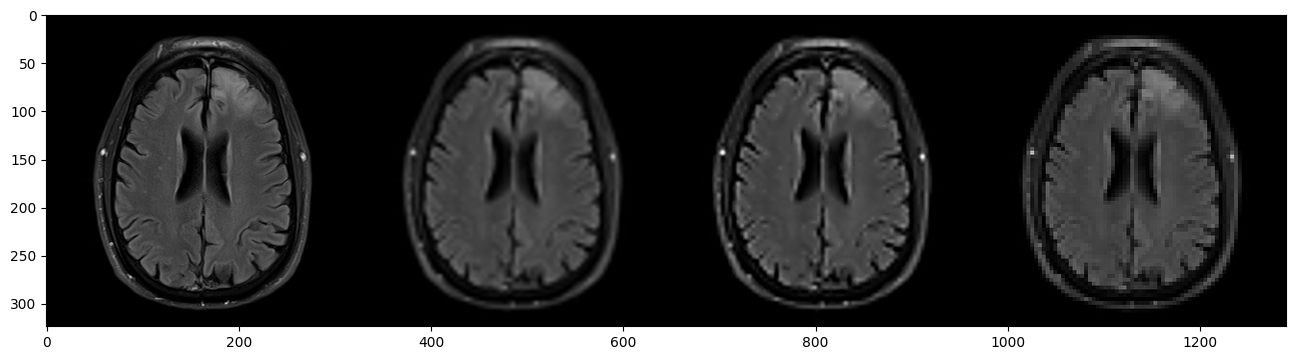

In [3]:
# Image and super-resolution configuration (based on the reference notebook)
path_to_image = "/content/brain.png" if os.path.exists("/content/brain.png") else "brain.png"
imsize = -1
factor = 4
enforse_div32 = "CROP"
PLOT = True

imgs = load_LR_HR_imgs_sr(
    path_to_image,
    imsize,
    factor,
    enforse_div32
)

imgs["bicubic_np"], imgs["sharp_np"], imgs["nearest_np"] = get_baselines(
    imgs["LR_pil"], imgs["HR_pil"]
)

print("HR shape:", imgs["HR_np"].shape)
print("LR shape:", imgs["LR_np"].shape)

if PLOT:
    plot_image_grid(
        [imgs["HR_np"], imgs["bicubic_np"], imgs["sharp_np"], imgs["nearest_np"]],
        4,
        12
    )
    plt.show()

In [4]:
# Training settings from the reference notebook
input_depth = 32
INPUT = "noise"
pad = "reflection"
KERNEL_TYPE = "lanczos2"

LR = 0.01
num_iter = 2000
LOSS_TYPE = "L1"

# Set to 0.0 to train both outputs only through LR data consistency.
# A positive value encourages the two HR reconstructions to agree.
CONSISTENCY_WEIGHT = 0.1

torch.manual_seed(1234)
np.random.seed(1234)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(1234)

## Create two independent noise vectors

Both vectors have the same shape but different random values. The same U-Net parameters are shared by both inputs.

In [5]:
height, width = imgs["HR_pil"].size[1], imgs["HR_pil"].size[0]

z1 = get_noise(input_depth, INPUT, (height, width)).detach().to(device)
z2 = get_noise(input_depth, INPUT, (height, width)).detach().to(device)

print("z1:", tuple(z1.shape))
print("z2:", tuple(z2.shape))
print("Same tensor values?", torch.equal(z1, z2))

z1: (1, 32, 320, 320)
z2: (1, 32, 320, 320)
Same tensor values? False


In [6]:
# Same U-Net architecture as the reference notebook
net = get_net(
    input_depth,
    "skip",
    pad,
    skip_n33d=128,
    skip_n33u=128,
    skip_n11=4,
    num_scales=5,
    upsample_mode="bilinear"
).to(device)

downsampler = Downsampler(
    n_planes=3,
    factor=factor,
    kernel_type=KERNEL_TYPE,
    phase=0.5,
    preserve_size=True
).to(device)

img_LR_var = np_to_torch(imgs["LR_np"]).to(device)

criterion = nn.L1Loss()
optimizer = torch.optim.Adam(net.parameters(), lr=LR)

print("Trainable parameters:", sum(p.numel() for p in net.parameters() if p.requires_grad))

Trainable parameters: 2217831


In [7]:
# Weights & Biases setup

In [13]:
import wandb

In [14]:
wandb.init()

In [15]:
wandb_run  = wandb.init(
    # Set the wandb entity where your project will be logged (generally your team name).
    entity="shriramgolla-iit-hyderabad",
    # Set the wandb project where this run will be logged.
    project="Medical Imaging",
    # Track hyperparameters and run metadata.
    config={
        "learning_rate": 0.01,
        "architecture": "UNet",
        "dataset": "Medical Images",
        "iters": 2000,
        "title" : "Two different Inputs"
    },
)

In [16]:
def to_wandb_image_array(image):
    """Convert a DIP/NumPy image to HWC format for wandb.Image."""
    image = np.asarray(image)
    if image.ndim == 3 and image.shape[0] in (1, 3, 4):
        image = np.transpose(image, (1, 2, 0))
    if image.ndim == 3 and image.shape[-1] == 1:
        image = image[..., 0]
    return np.clip(image, 0, 1).astype(np.float32)

print("W&B run:", wandb_run.url)


W&B run: https://wandb.ai/shriramgolla-iit-hyderabad/Medical%20Imaging/runs/s3cq0fvx


## Train the shared DIP U-Net

At every iteration, both outputs are compared with the same low-resolution observation. The combined data loss is the mean of the two L1 losses. An optional consistency term encourages both HR predictions to be similar.

In [18]:
history = []
best_mean_psnr = -float("inf")
start_time = time.time()

for iteration in range(num_iter):
    net.train()
    optimizer.zero_grad(set_to_none=True)

    # Two outputs from the same network, using independent fixed noise inputs
    out1 = net(z1)
    out2 = net(z2)

    # Both are constrained to match the SAME observed LR image
    lr1 = downsampler(out1)
    lr2 = downsampler(out2)

    loss1 = criterion(lr1, img_LR_var)
    loss2 = criterion(lr2, img_LR_var)
    loss_data = 0.5 * (loss1 + loss2)

    # Optional HR-output agreement term
    loss_consistency = criterion(out1, out2)

    loss_total = loss_data + CONSISTENCY_WEIGHT * loss_consistency
    loss_total.backward()
    optimizer.step()

    if iteration % 25 == 0 or iteration == num_iter - 1:
        net.eval()
        with torch.no_grad():
            # Evaluate after the parameter update
            pred1 = net(z1).clamp(0, 1)
            pred2 = net(z2).clamp(0, 1)
            pred_mean = 0.5 * (pred1 + pred2)

            pred1_np = torch_to_np(pred1)
            pred2_np = torch_to_np(pred2)
            pred_mean_np = torch_to_np(pred_mean)

            psnr1 = peak_signal_noise_ratio(
                imgs["HR_np"], np.clip(pred1_np, 0, 1), data_range=1.0
            )
            psnr2 = peak_signal_noise_ratio(
                imgs["HR_np"], np.clip(pred2_np, 0, 1), data_range=1.0
            )
            psnr_mean = peak_signal_noise_ratio(
                imgs["HR_np"], np.clip(pred_mean_np, 0, 1), data_range=1.0
            )

            lr1_eval = downsampler(pred1)
            lr2_eval = downsampler(pred2)
            lr_loss1_eval = criterion(lr1_eval, img_LR_var).item()
            lr_loss2_eval = criterion(lr2_eval, img_LR_var).item()

        history.append({
            "iteration": iteration,
            "total_loss": float(loss_total.item()),
            "loss_data": float(loss_data.item()),
            "loss1": float(loss1.item()),
            "loss2": float(loss2.item()),
            "loss_consistency": float(loss_consistency.item()),
            "lr_loss1_eval": lr_loss1_eval,
            "lr_loss2_eval": lr_loss2_eval,
            "psnr_output1": float(psnr1),
            "psnr_output2": float(psnr2),
            "psnr_average": float(psnr_mean),
        })

        best_mean_psnr = max(best_mean_psnr, psnr_mean)

        # Log scalar metrics at every evaluation checkpoint.
        wandb_payload = {
            "train/total_loss": float(loss_total.item()),
            "train/data_loss": float(loss_data.item()),
            "train/lr_loss_z1": float(loss1.item()),
            "train/lr_loss_z2": float(loss2.item()),
            "train/consistency_loss": float(loss_consistency.item()),
            "eval/lr_loss_z1": float(lr_loss1_eval),
            "eval/lr_loss_z2": float(lr_loss2_eval),
            "eval/psnr_z1_db": float(psnr1),
            "eval/psnr_z2_db": float(psnr2),
            "eval/psnr_average_db": float(psnr_mean),
            "training/best_sampled_average_psnr_db": float(best_mean_psnr),
        }

        # Intermediate image logging is less frequent to keep W&B uploads small.
        if iteration % 100 == 0 or iteration == num_iter - 1:
            wandb_payload.update({
                "images/output_z1": wandb.Image(
                    to_wandb_image_array(pred1_np), caption=f"DIP output from z1 at iteration {iteration}"
                ),
                "images/output_z2": wandb.Image(
                    to_wandb_image_array(pred2_np), caption=f"DIP output from z2 at iteration {iteration}"
                ),
                "images/mean_output": wandb.Image(
                    to_wandb_image_array(pred_mean_np), caption=f"Mean of outputs at iteration {iteration}"
                ),
            })

        wandb.log(wandb_payload, step=iteration)

        print(
            f"Iter {iteration:04d} | total={loss_total.item():.6f} "
            f"| L1(z1)={loss1.item():.6f} | L1(z2)={loss2.item():.6f} "
            f"| consistency={loss_consistency.item():.6f} "
            f"| PSNRs=({psnr1:.3f}, {psnr2:.3f}, avg {psnr_mean:.3f})"
        )

elapsed = time.time() - start_time
print(f"Training finished in {elapsed / 60:.2f} minutes.")
print(f"Best sampled average-output PSNR: {best_mean_psnr:.3f} dB")

Iter 0000 | total=0.348478 | L1(z1)=0.331573 | L1(z2)=0.337407 | consistency=0.139883 | PSNRs=(8.533, 8.536, avg 8.534)
Iter 0025 | total=0.038389 | L1(z1)=0.037188 | L1(z2)=0.038337 | consistency=0.006271 | PSNRs=(18.252, 19.527, avg 19.016)
Iter 0050 | total=0.018712 | L1(z1)=0.017820 | L1(z2)=0.017719 | consistency=0.009427 | PSNRs=(24.853, 25.094, avg 25.347)
Iter 0075 | total=0.011813 | L1(z1)=0.011101 | L1(z2)=0.010928 | consistency=0.007984 | PSNRs=(28.803, 28.697, avg 29.138)
Iter 0100 | total=0.008067 | L1(z1)=0.007318 | L1(z2)=0.007505 | consistency=0.006552 | PSNRs=(29.474, 30.621, avg 30.467)
Iter 0125 | total=0.006177 | L1(z1)=0.005716 | L1(z2)=0.005349 | consistency=0.006439 | PSNRs=(30.526, 30.906, avg 31.097)
Iter 0150 | total=0.005260 | L1(z1)=0.004647 | L1(z2)=0.004761 | consistency=0.005567 | PSNRs=(31.317, 31.084, avg 31.560)
Iter 0175 | total=0.007946 | L1(z1)=0.007608 | L1(z2)=0.006956 | consistency=0.006644 | PSNRs=(30.216, 29.524, avg 30.201)
Iter 0200 | total=0

## Final reconstructions and metrics

The notebook reports the two predictions separately and their pixelwise average. The average is an additional combined output; it is not a substitute for reporting both individual predictions.

In [21]:
def plot_image_grid(images_np, labels=None, nrow=8,
                    interpolation='lanczos'):
    """
    Draw images in a grid with labels.

    Args:
        images_np: list of images, each image is np.array of size CxHxW
        labels: list of labels, one for each image
        nrow: number of images per row
        factor: figure size factor
        interpolation: interpolation used in plt.imshow
    """
    n_images = len(images_np)
    if labels is None:
        labels = [''] * n_images
    assert len(labels) == n_images, \
        "Number of labels must match number of images"
    n_channels = max(x.shape[0] for x in images_np)
    ncols = min(nrow, n_images)
    nrows = int(np.ceil(n_images / ncols))
    fig, axes = plt.subplots(nrows,ncols,figsize=(4 * ncols, 2.75 * nrows))
    axes = np.array(axes).reshape(-1)
    for i, (image, label) in enumerate(zip(images_np, labels)):
        ax = axes[i]
        ax.imshow(image.transpose(1, 2, 0),interpolation=interpolation)
        ax.set_title(label, fontsize=8)
    plt.tight_layout()
    return fig

{'output_z1': {'PSNR': 32.06119907863804, 'SSIM': 0.8939436078071594}, 'output_z2': {'PSNR': 32.01177917953072, 'SSIM': 0.8933432698249817}, 'average_output': {'PSNR': 32.06227340759416, 'SSIM': 0.8942674994468689}}


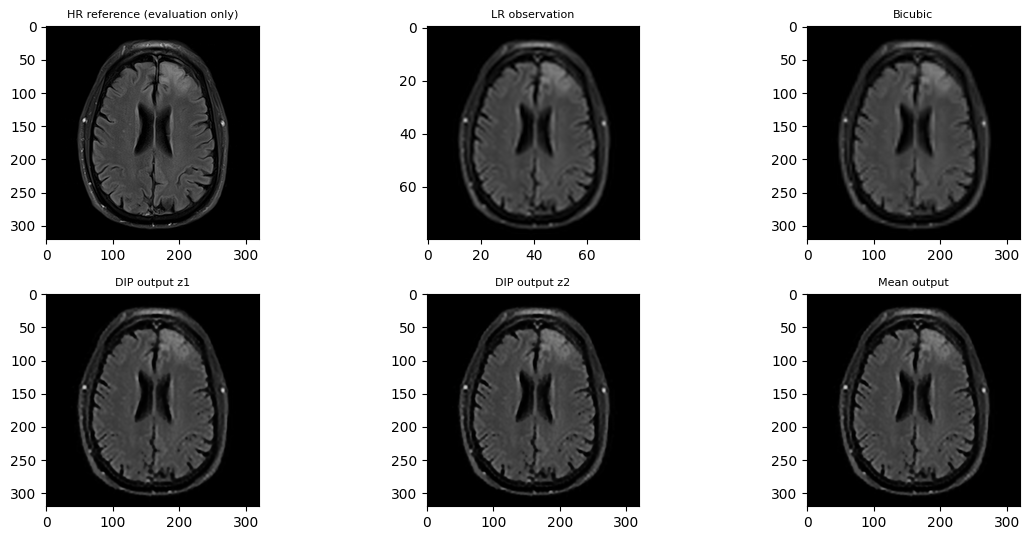

Final metrics and images logged to W&B.


In [22]:
net.eval()
with torch.no_grad():
    out1_final = net(z1).clamp(0, 1)
    out2_final = net(z2).clamp(0, 1)
    out_avg_final = 0.5 * (out1_final + out2_final)

out1_np = np.clip(torch_to_np(out1_final), 0, 1)
out2_np = np.clip(torch_to_np(out2_final), 0, 1)
out_avg_np = np.clip(torch_to_np(out_avg_final), 0, 1)

def compute_metrics(pred, target):
    pred = np.clip(pred, 0, 1).astype(np.float32)
    target = np.clip(target, 0, 1).astype(np.float32)
    ssim = structural_similarity(
        target, pred, data_range=1.0, channel_axis=0
    )
    psnr = peak_signal_noise_ratio(target, pred, data_range=1.0)
    return {"PSNR": float(psnr), "SSIM": float(ssim)}

metrics = {
    "output_z1": compute_metrics(out1_np, imgs["HR_np"]),
    "output_z2": compute_metrics(out2_np, imgs["HR_np"]),
    "average_output": compute_metrics(out_avg_np, imgs["HR_np"]),
}

print(metrics)

plot_image_grid(
    [imgs["HR_np"], imgs["LR_np"], imgs["bicubic_np"], out1_np, out2_np, out_avg_np],
    labels=["HR reference (evaluation only)", "LR observation", "Bicubic", "DIP output z1", "DIP output z2", "Mean output"],
    nrow=3
)
plt.show()

# Log final PSNR/SSIM and final reconstructions to W&B.
final_wandb_payload = {
    "final/psnr_z1_db": metrics["output_z1"]["PSNR"],
    "final/ssim_z1": metrics["output_z1"]["SSIM"],
    "final/psnr_z2_db": metrics["output_z2"]["PSNR"],
    "final/ssim_z2": metrics["output_z2"]["SSIM"],
    "final/psnr_average_db": metrics["average_output"]["PSNR"],
    "final/ssim_average": metrics["average_output"]["SSIM"],
    "final/images/hr_reference": wandb.Image(
        to_wandb_image_array(imgs["HR_np"]), caption="HR reference (evaluation only)"
    ),
    "final/images/lr_observation": wandb.Image(
        to_wandb_image_array(imgs["LR_np"]), caption="Low-resolution observation"
    ),
    "final/images/bicubic_baseline": wandb.Image(
        to_wandb_image_array(imgs["bicubic_np"]), caption="Bicubic baseline"
    ),
    "final/images/output_z1": wandb.Image(
        to_wandb_image_array(out1_np), caption="Final output from z1"
    ),
    "final/images/output_z2": wandb.Image(
        to_wandb_image_array(out2_np), caption="Final output from z2"
    ),
    "final/images/average_output": wandb.Image(
        to_wandb_image_array(out_avg_np), caption="Final average output"
    ),
}
wandb.log(final_wandb_payload, step=num_iter)
print("Final metrics and images logged to W&B.")


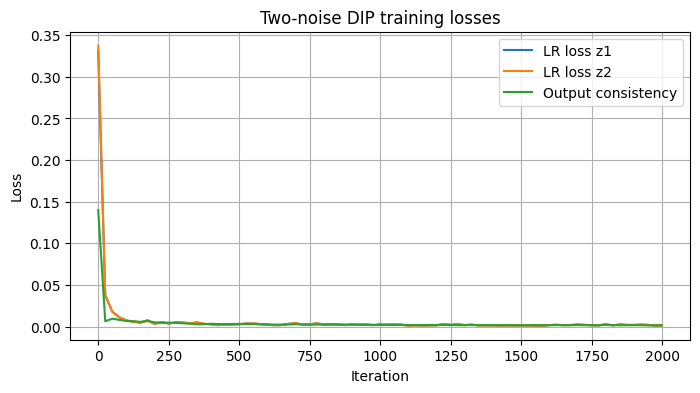

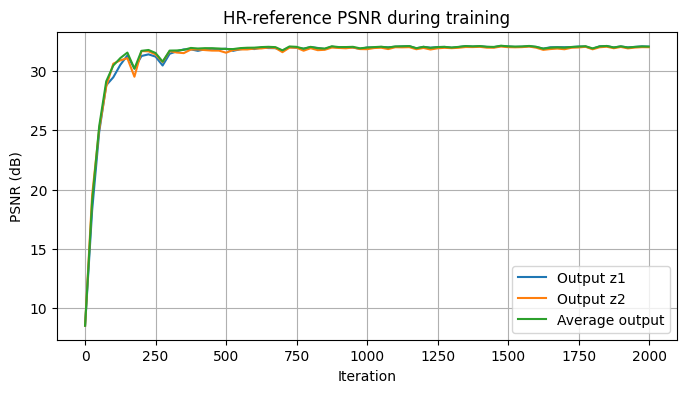

In [23]:
# Plot the losses and PSNR sampled during training
if history:
    steps = [row["iteration"] for row in history]

    plt.figure(figsize=(8, 4))
    plt.plot(steps, [row["loss1"] for row in history], label="LR loss z1")
    plt.plot(steps, [row["loss2"] for row in history], label="LR loss z2")
    plt.plot(steps, [row["loss_consistency"] for row in history], label="Output consistency")
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.title("Two-noise DIP training losses")
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.plot(steps, [row["psnr_output1"] for row in history], label="Output z1")
    plt.plot(steps, [row["psnr_output2"] for row in history], label="Output z2")
    plt.plot(steps, [row["psnr_average"] for row in history], label="Average output")
    plt.xlabel("Iteration")
    plt.ylabel("PSNR (dB)")
    plt.title("HR-reference PSNR during training")
    plt.legend()
    plt.grid(True)
    plt.show()

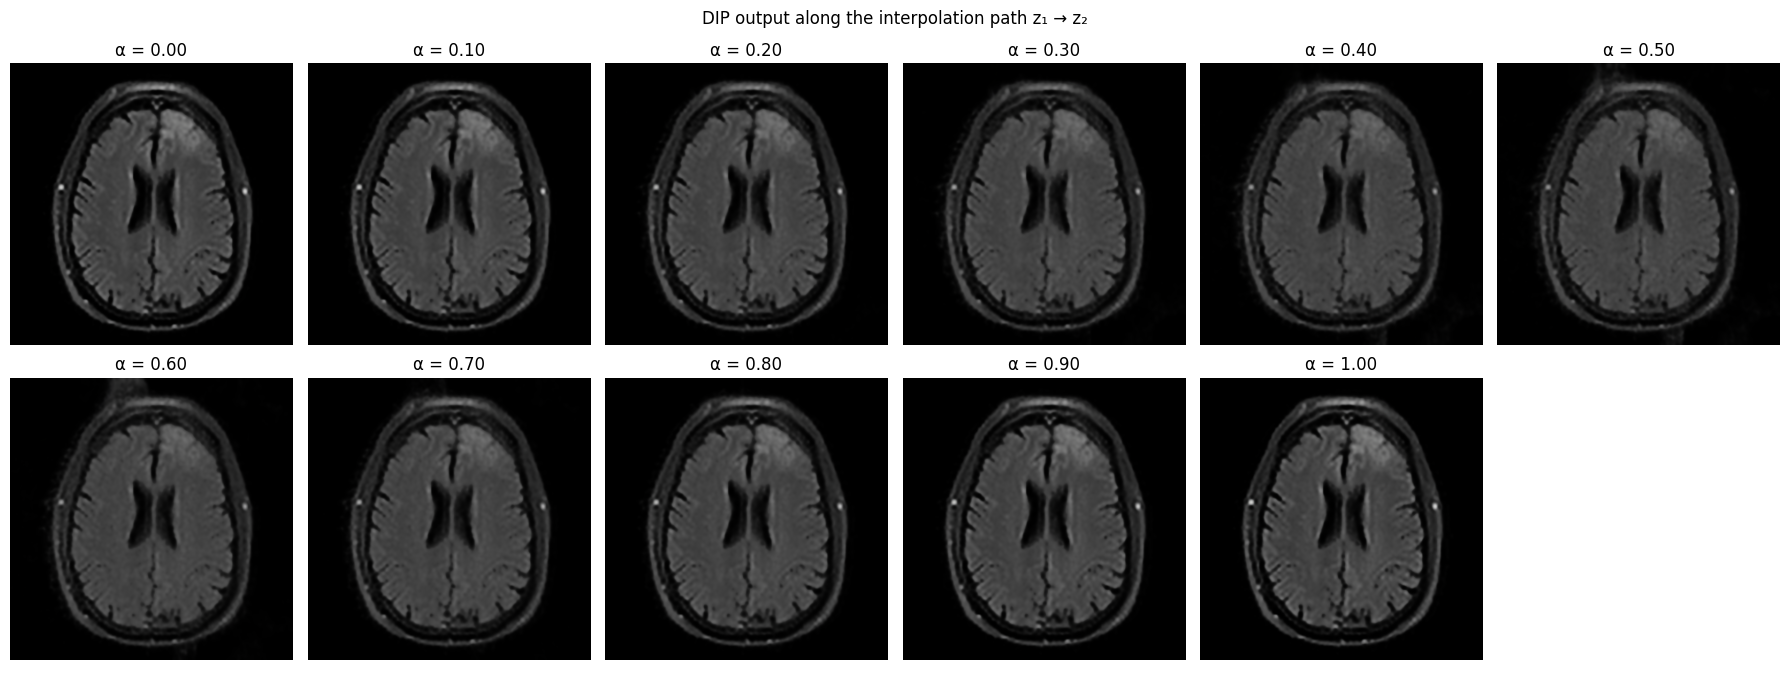

In [24]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# Use your existing trained DIP network.
net.eval()

# Number of interpolation points
num_steps = 11
alphas = torch.linspace(0, 1, num_steps)

interpolated_images = []

with torch.no_grad():
    for alpha in alphas:
        z_alpha = (1 - alpha) * z1 + alpha * z2

        # Same trained U-Net; only the input noise changes.
        output = net(z_alpha).clamp(0, 1)

        interpolated_images.append(
            output[0].detach().cpu().permute(1, 2, 0).numpy()
        )

# Visualize all outputs
fig, axes = plt.subplots(2, 6, figsize=(18, 7))
axes = axes.flatten()

for i, (alpha, image) in enumerate(
    zip(alphas.numpy(), interpolated_images)
):
    axes[i].imshow(image.squeeze(), cmap="gray"
                   if image.shape[-1] == 1 else None)
    axes[i].set_title(f"α = {alpha:.2f}")
    axes[i].axis("off")

for i in range(num_steps, len(axes)):
    axes[i].axis("off")

plt.suptitle("DIP output along the interpolation path z₁ → z₂")
plt.tight_layout()
plt.show()

In [33]:
import pandas as pd
rows = []


for alpha in alphas:
    z_alpha = (1 - alpha) * z1 + alpha * z2
    out_HR_r = net(z_alpha).clamp(0, 1)
    out_HR_r_np = np.clip(torch_to_np(out_HR_r), 0, 1)
    out_LR_r = downsampler(out_HR_r)
    psnr = peak_signal_noise_ratio(
                imgs["HR_np"], out_HR_r_np
            )

    rows.append({
        "alpha": float(alpha),
        "PSNR_dB": float(psnr),
        "MSE_from_z1_output": float(
            np.mean((image - interpolated_images[0]) ** 2)
        )
    })

# Display results
psnr_table = pd.DataFrame(rows)
display(psnr_table.round(4))


# Log to W&B
# Use your active run object here.
with wandb_run:
    wandb_run.log({
        "noise_interpolation/table": wandb.Table(dataframe=psnr_table),
        "noise_interpolation/psnr_vs_alpha": wandb.plot.line(
            wandb.Table(dataframe=psnr_table),
            "alpha",
            "PSNR_dB",
            title="PSNR vs Noise Interpolation"
        )
    })

    # Log each output image with its alpha and PSNR.
    wandb_run.log({
        "noise_interpolation/images": [
            wandb.Image(
                image,
                caption=f"alpha={row['alpha']:.2f}, "
                        f"PSNR={row['PSNR_dB']:.3f} dB"
            )
            for image, row in zip(interpolated_images, rows)
        ]
    })

,alpha,PSNR_dB,MSE_from_z1_output
0,0.0,32.0612,0.0
1,0.1,31.9742,0.0
2,0.2,31.3153,0.0
3,0.3,30.2974,0.0
4,0.4,29.3734,0.0
5,0.5,28.9222,0.0
6,0.6,29.0151,0.0
7,0.7,30.4943,0.0
8,0.8,31.5196,0.0
9,0.9,32.0630,0.0


eval/lr_loss_z1,█▄▂▃▂▂▁▁▂▁▁▂▁▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
eval/lr_loss_z2,█▄▃▂▁▂▁▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
eval/psnr_average_db,▁▄▆█████████████████████████████████████
eval/psnr_z1_db,▁▄▇█████████████████████████████████████
eval/psnr_z2_db,▁▄▇▇████████████████████████████████████
final/psnr_average_db,▁
final/psnr_z1_db,▁
final/psnr_z2_db,▁
final/ssim_average,▁
final/ssim_z1,▁
+7,...


## Interpretation notes

- The same U-Net weights are used for both noise inputs; the model is trained jointly on both.
- Both outputs are compared against the same LR observation through the same downsampler.
- The HR reference is used only for evaluation and PSNR/SSIM, not as a training target.
- `CONSISTENCY_WEIGHT = 0.0` removes the output-agreement penalty. Use a positive value if the objective is for the two HR predictions to be similar.
- This is different from training two independent DIP networks: there is one shared parameter set.
- W&B logs training losses and PSNR at each evaluation checkpoint, intermediate reconstructions every `WANDB_IMAGE_LOG_EVERY` iterations, and final PSNR/SSIM plus final images.
- If you do not want to upload intermediate images frequently, increase `WANDB_IMAGE_LOG_EVERY`.
